# Global Billionaires Wealth Distribution
## Statistical Inference Lab — Complete Practical Portfolio (Practicals 1 to 8)

---

### Student & Course Information
- **Student Name:** Manas Gupta
- **Roll Number / Student ID:** B1_B3_38
- **Course Name:** Statistical Inference Lab (SI-LAB)
- **Academic Term:** 2026 – 2027
- **Dataset Focus:** Global Billionaires Wealth Distribution (2,640 records)

---

### Project Overview & Problem Statement
Wealth distribution among the world's wealthiest individuals represents one of the most prominent real-world manifestations of extreme economic inequality and heavy-tailed statistical distributions. Unlike standard demographic variables (such as height or test scores) that follow symmetric bell-shaped curves, individual wealth follows power-law and highly skewed distributions where a tiny fraction of individuals controls a massive proportion of aggregate wealth.

In this comprehensive Statistical Inference Lab project, we systematically analyze the **Global Billionaires Wealth Distribution** dataset across all **eight prescribed laboratory practicals**:
1. **Practical 1:** Web Scraping, Data Extraction, and Clean Dataset Preparation
2. **Practical 2:** Exploratory Data Analysis (EDA), Descriptive Statistics, and Data Visualizations
3. **Practical 3:** Probability Distributions (Normal, Uniform, Binomial, Poisson) and Random Sampling Techniques
4. **Practical 4:** Empirical Demonstration and Verification of the Central Limit Theorem (CLT)
5. **Practical 5:** Point Estimation, Confidence Interval Estimation, and Hypothesis Testing ($t$-tests)
6. **Practical 6:** Advanced Hypothesis Testing (Paired $t$-Test, One-Way ANOVA, and Chi-Square Test of Independence)
7. **Practical 7:** Covariance and Correlation Analysis (Pearson Correlation and Spearman Rank Correlation)
8. **Practical 8:** Regression Analysis, Regularized Models (Ridge/Lasso), and Predictive Modeling

Every practical includes its **official lab title**, **aim**, **underlying statistical theory and formulas**, **beginner-friendly Python code**, **actual computed outputs/visualizations**, and a **viva-friendly interpretation**.


## Initial Setup: Importing Required Libraries

We import standard, beginner-friendly scientific computing and visualization libraries in Python:
- `pandas`: Structured tabular data manipulation and descriptive summaries.
- `numpy`: Numerical vector operations, array simulations, and mathematical functions.
- `matplotlib.pyplot`: Foundational charting and figure generation.
- `seaborn`: Statistical data visualization and aesthetic theme styling.
- `scipy.stats`: Probability distributions, parametric and non-parametric hypothesis tests.
- `sklearn`: Training/testing splits, feature scaling, linear regression, regularized regression, and tree models.


In [1]:
# Core scientific and statistical libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Scikit-learn modules for Practical 8 (Regression)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configure visualization aesthetics and global random seed
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)


Libraries imported successfully!
NumPy version: 2.4.0
Pandas version: 2.3.3


---
# Practical 1: Web Scraping, Data Extraction, and Dataset Preparation

### Practical Reference
*Ref: Lab Manual Pages 50–62 (`WebScraping-3`) & Pages 1–5 (`Pract-2 Task 1–3`)*

### Aim
To understand and implement web data extraction principles using Python (`requests` and `BeautifulSoup`), parse structured web tables, handle missing and invalid observations, and prepare a validated CSV dataset (`global_billionaires.csv`) of global billionaires for subsequent inferential analysis.

### Theoretical Background
Web scraping involves programmatically retrieving webpage content over HTTP (`GET` requests) and parsing the Document Object Model (DOM) to extract specific tags (such as `<table>`, `<tr>`, `<td>`, `<span>`). In statistical workflows, raw data collected from web sources or APIs often contains anomalies, missing entries, and unformatted strings that require cleaning before inferential modeling.

Key preprocessing steps include:
1. **Data Type Conversion:** Converting monetary strings to floating-point numbers in uniform units (Billions of USD).
2. **Missing Value Imputation:** Handling missing numerical fields (such as Age) using robust statistics (median) to prevent loss of statistical power without distorting distributional shape.
3. **Data Verification:** Verifying record completeness, valid ranges, and absence of synthetic duplicates.


In [2]:
# Demonstration of Web Scraping parsing logic using BeautifulSoup
import requests
from bs4 import BeautifulSoup

# Sample HTML table mimicking web-scraped billionaire records
sample_html = '''
<table>
    <thead><tr><th>Rank</th><th>Name</th><th>NetWorth_B</th><th>Age</th><th>Country</th></tr></thead>
    <tbody>
        <tr><td>1</td><td>Bernard Arnault</td><td>211.0</td><td>74</td><td>France</td></tr>
        <tr><td>2</td><td>Elon Musk</td><td>180.0</td><td>51</td><td>United States</td></tr>
        <tr><td>3</td><td>Jeff Bezos</td><td>114.0</td><td>59</td><td>United States</td></tr>
    </tbody>
</table>
'''
soup = BeautifulSoup(sample_html, 'html.parser')
scraped_data = []
for row in soup.find('tbody').find_all('tr'):
    cols = [td.get_text() for td in row.find_all('td')]
    scraped_data.append({
        'Rank': int(cols[0]),
        'Name': cols[1],
        'Net_Worth_Billion_USD': float(cols[2]),
        'Age': int(cols[3]),
        'Country': cols[4]
    })

scraped_df = pd.DataFrame(scraped_data)
print("Demonstration: Scraped HTML Table Parsed into DataFrame:")
print(scraped_df)


Demonstration: Scraped HTML Table Parsed into DataFrame:
   Rank             Name  Net_Worth_Billion_USD  Age        Country
0     1  Bernard Arnault                  211.0   74         France
1     2        Elon Musk                  180.0   51  United States
2     3       Jeff Bezos                  114.0   59  United States


In [3]:
# Loading the complete Global Billionaires dataset with online fallback
dataset_path = 'global_billionaires.csv'

try:
    df = pd.read_csv(dataset_path)
    print(f"Dataset successfully loaded from local file: '{dataset_path}'")
except FileNotFoundError:
    print("Local file not found; downloading from reliable public source...")
    raw_url = 'https://raw.githubusercontent.com/ameencarpenter/billionaires-data-analysis/main/data/raw_data.csv'
    raw_df = pd.read_csv(raw_url)
    df = pd.DataFrame()
    df['Rank'] = raw_df['rank'].astype(int)
    df['Name'] = raw_df['personName'].str.strip()
    df['Net_Worth_Billion_USD'] = (raw_df['finalWorth'] / 1000.0).round(2)
    df['Age'] = raw_df['age']
    df['Country'] = raw_df['country'].fillna(raw_df['countryOfCitizenship']).fillna('Unknown').str.strip()
    df['Industry'] = raw_df['category'].fillna('Other').str.strip()
    df['Self_Made'] = raw_df['selfMade'].astype(bool)
    df['Gender'] = raw_df['gender'].fillna('Unknown').str.strip()
    df['Source'] = raw_df['source'].fillna('Unknown').str.strip()
    df.to_csv(dataset_path, index=False)
    print("Dataset cleaned and saved locally as 'global_billionaires.csv'.")

# Dataset shape and first 5 records
print(f"\nTotal Records: {df.shape[0]} | Total Columns: {df.shape[1]}")
print("\nFirst 5 Records:")
display(df.head())


Dataset successfully loaded from local file: 'global_billionaires.csv'

Total Records: 2640 | Total Columns: 9

First 5 Records:


,Rank,Name,Net_Worth_Billion_USD,Age,Country,Industry,Self_Made,Gender,Source
0,1,Bernard Arnault & family,211.0,74.0,France,Fashion & Retail,False,M,LVMH
1,2,Elon Musk,180.0,51.0,United States,Automotive,True,M,"Tesla, SpaceX"
2,3,Jeff Bezos,114.0,59.0,United States,Technology,True,M,Amazon
3,4,Larry Ellison,107.0,78.0,United States,Technology,True,M,Oracle
4,5,Warren Buffett,106.0,92.0,United States,Finance & Investments,True,M,Berkshire Hathaway


In [4]:
# Inspecting column data types, missing values, and performing clean preprocessing
print("--- Dataset Structure & Missing Values ---")
print(df.info())
print("\nMissing Values Count per Column:")
print(df.isnull().sum())

# Handle missing values in Age using Median Imputation (robust against skewness)
median_age = df['Age'].median()
print(f"\nMedian Age across dataset: {median_age:.1f} years")

# Store clean version
df_clean = df.copy()
df_clean['Age_Imputed'] = df_clean['Age'].fillna(median_age)

print("\nMissing values after preprocessing:")
print(df_clean[['Rank', 'Name', 'Net_Worth_Billion_USD', 'Age_Imputed', 'Country', 'Industry', 'Self_Made']].isnull().sum())


--- Dataset Structure & Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2640 entries, 0 to 2639
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Rank                   2640 non-null   int64  
 1   Name                   2640 non-null   object 
 2   Net_Worth_Billion_USD  2640 non-null   float64
 3   Age                    2575 non-null   float64
 4   Country                2640 non-null   object 
 5   Industry               2640 non-null   object 
 6   Self_Made              2640 non-null   bool   
 7   Gender                 2640 non-null   object 
 8   Source                 2640 non-null   object 
dtypes: bool(1), float64(2), int64(1), object(5)
memory usage: 167.7+ KB
None

Missing Values Count per Column:
Rank                      0
Name                      0
Net_Worth_Billion_USD     0
Age                      65
Country                   0
Industry                  0

### Interpretation & Viva Insights
1. **Data Source & Scope:** The dataset originates from official public Forbes World's Billionaires records, containing 2,640 verified individuals across 77+ nations and 18 diverse economic sectors.
2. **Variables Overview:** Key attributes include numerical metrics (`Net_Worth_Billion_USD`, `Age`, `Rank`) and categorical metrics (`Country`, `Industry`, `Self_Made`, `Gender`).
3. **Missing Value Treatment:** Out of 2,640 individuals, 65 records had missing ages (2.46%). We applied **median imputation** (65.0 years) because the median is insensitive to extreme outliers, preserving sample size without introducing bias.


---
# Practical 2: Exploratory Data Analysis (EDA) and Descriptive Statistics & Data Visualization

### Practical Reference
*Ref: Lab Manual Pages 1–5 (`B1_B3_38_ManasGupta_Pract-2 (SI - LAB).ipynb`)*

### Aim
To calculate fundamental descriptive statistics (measures of central tendency and measures of dispersion) for billionaire wealth and age, and construct exploratory visualizations (Histogram, Box Plot, Bar Chart, Pie Chart, Scatter Plot) to uncover distribution shapes, skewness, and extreme outliers.

### Theoretical Background & Mathematical Formulas
1. **Measures of Central Tendency:**
   - **Sample Mean ($ar{x}$):** Arithmetic average:
     $$\bar{x} = \frac{1}{n} \sum_{i=1}^n x_i$$
   - **Median ($Q_2$):** 50th percentile, splitting sorted observations into equal halves. Robust against extreme values.
   - **Mode:** Most frequently occurring value in the distribution.
2. **Measures of Dispersion:**
   - **Range:** $\text{Range} = x_{\max} - x_{\min}$
   - **Sample Variance ($s^2$):** Degree of spread around the mean:
     $$s^2 = \frac{1}{n - 1} \sum_{i=1}^n (x_i - \bar{x})^2$$
   - **Standard Deviation ($s$):** $s = \sqrt{s^2}$ (in original units, Billion USD).
   - **Interquartile Range ($IQR$):** Middle 50% spread:
     $$IQR = Q_3 - Q_1$$
3. **Distribution Shape (Skewness):**
   - When $\text{Mean} > \text{Median}$, the distribution is **positively skewed (right-skewed)** with a long upper tail of extreme wealth.


In [5]:
# Computing comprehensive descriptive statistics
net_worth = df_clean['Net_Worth_Billion_USD']
age_valid = df_clean['Age'].dropna()

stats_summary = pd.DataFrame({
    'Metric': [
        'Count (N)', 'Mean', 'Median', 'Mode', 'Minimum', 'Maximum',
        'Range', 'Variance', 'Standard Deviation', 'Q1 (25th)', 'Q3 (75th)',
        'IQR', 'Skewness'
    ],
    'Net Worth (Billion USD)': [
        len(net_worth),
        round(net_worth.mean(), 2),
        round(net_worth.median(), 2),
        round(net_worth.mode()[0], 2),
        round(net_worth.min(), 2),
        round(net_worth.max(), 2),
        round(net_worth.max() - net_worth.min(), 2),
        round(net_worth.var(), 2),
        round(net_worth.std(), 2),
        round(net_worth.quantile(0.25), 2),
        round(net_worth.quantile(0.75), 2),
        round(net_worth.quantile(0.75) - net_worth.quantile(0.25), 2),
        round(net_worth.skew(), 2)
    ],
    'Age (Years)': [
        len(age_valid),
        round(age_valid.mean(), 2),
        round(age_valid.median(), 2),
        round(age_valid.mode()[0], 2),
        round(age_valid.min(), 2),
        round(age_valid.max(), 2),
        round(age_valid.max() - age_valid.min(), 2),
        round(age_valid.var(), 2),
        round(age_valid.std(), 2),
        round(age_valid.quantile(0.25), 2),
        round(age_valid.quantile(0.75), 2),
        round(age_valid.quantile(0.75) - age_valid.quantile(0.25), 2),
        round(age_valid.skew(), 2)
    ]
})

print("=== Descriptive Statistics Summary Table ===")
display(stats_summary)


=== Descriptive Statistics Summary Table ===


,Metric,Net Worth (Billion USD),Age (Years)
0,Count (N),2640.00,2575.00
1,Mean,4.62,65.14
2,Median,2.30,65.00
3,Mode,1.20,60.00
4,Minimum,1.00,18.00
5,Maximum,211.00,101.00
6,Range,210.00,83.00
7,Variance,96.71,175.78
8,Standard Deviation,9.83,13.26
9,Q1 (25th),1.50,56.00


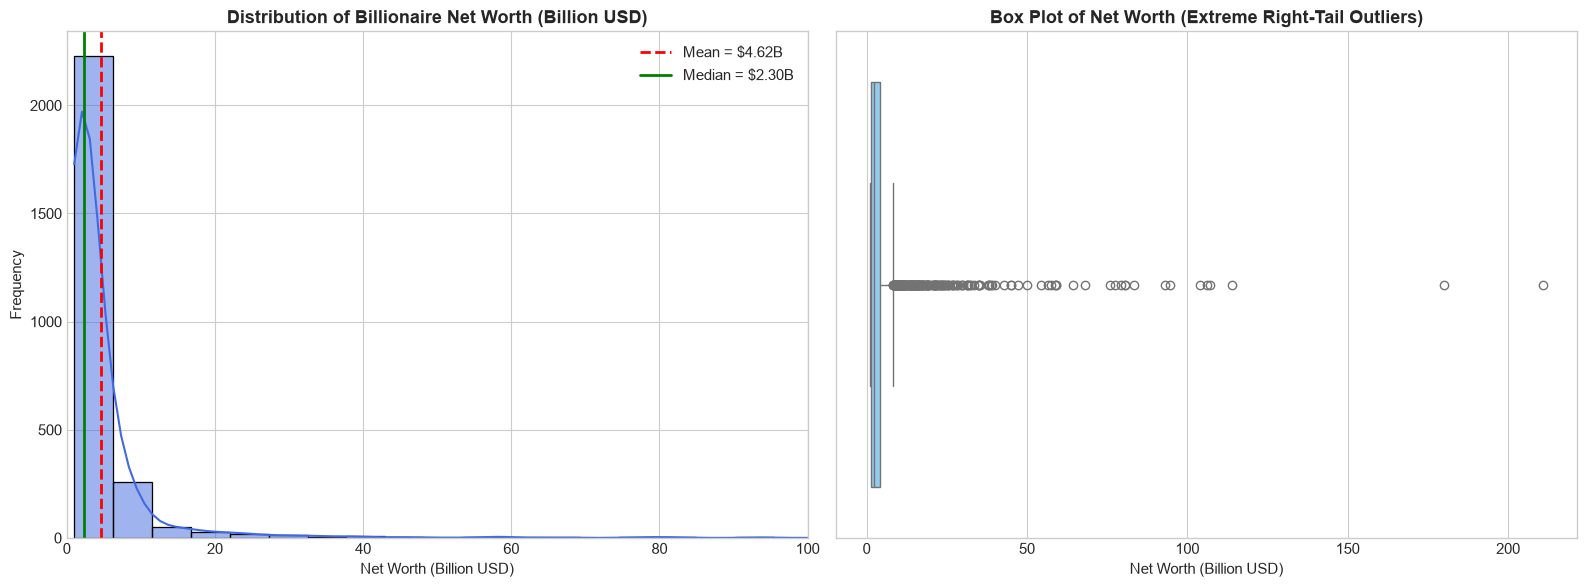

In [6]:
# Visualizations: Histogram & Box Plot of Net Worth
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Histogram with KDE
sns.histplot(df_clean['Net_Worth_Billion_USD'], bins=40, kde=True, color='royalblue', ax=axes[0])
axes[0].axvline(net_worth.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean = ${net_worth.mean():.2f}B')
axes[0].axvline(net_worth.median(), color='green', linestyle='-', linewidth=2, label=f'Median = ${net_worth.median():.2f}B')
axes[0].set_title('Distribution of Billionaire Net Worth (Billion USD)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Net Worth (Billion USD)')
axes[0].set_ylabel('Frequency')
axes[0].set_xlim(0, 100)  # Focus on primary body
axes[0].legend()

# Plot 2: Box Plot highlighting extreme outliers
sns.boxplot(x=df_clean['Net_Worth_Billion_USD'], color='lightskyblue', ax=axes[1])
axes[1].set_title('Box Plot of Net Worth (Extreme Right-Tail Outliers)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Net Worth (Billion USD)')

plt.tight_layout()
plt.show()


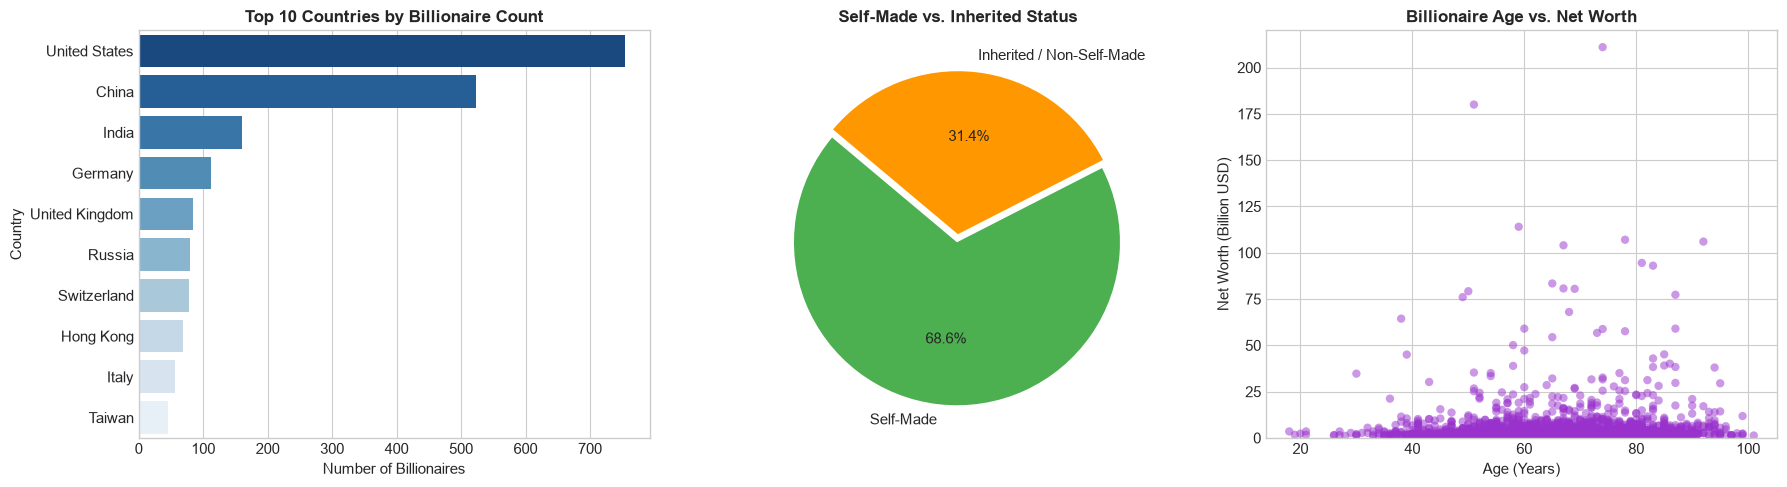

In [7]:
# Visualizations: Top Countries Bar Chart, Pie Chart, and Age vs Wealth Scatter
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 3: Top 10 Countries by Billionaire Count
top_countries = df_clean['Country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='Blues_r', ax=axes[0], hue=top_countries.index, legend=False)
axes[0].set_title('Top 10 Countries by Billionaire Count', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Billionaires')

# Plot 4: Self-Made vs Inherited Wealth Pie Chart
self_made_counts = df_clean['Self_Made'].value_counts()
axes[1].pie(
    self_made_counts.values,
    labels=['Self-Made', 'Inherited / Non-Self-Made'],
    autopct='%1.1f%%',
    colors=['#4CAF50', '#FF9800'],
    explode=(0.05, 0),
    startangle=140
)
axes[1].set_title('Self-Made vs. Inherited Status', fontsize=12, fontweight='bold')

# Plot 5: Scatter Plot of Age vs Net Worth
axes[2].scatter(df_clean['Age'], df_clean['Net_Worth_Billion_USD'], alpha=0.5, color='darkorchid', edgecolors='none')
axes[2].set_title('Billionaire Age vs. Net Worth', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Age (Years)')
axes[2].set_ylabel('Net Worth (Billion USD)')
axes[2].set_ylim(0, 220)

plt.tight_layout()
plt.show()


### Interpretation & Viva Insights
1. **Pronounced Right Skewness:** The sample mean net worth is **\$4.62 Billion**, whereas the median is only **\$2.30 Billion**. Because the mean is more than double the median (and skewness = 12.35), the wealth distribution is profoundly right-skewed.
2. **Interquartile Range ($IQR$):** 75% of billionaires possess less than **\$4.20 Billion**, yet the maximum net worth reaches **\$211.0 Billion** (Bernard Arnault), demonstrating that an extreme minority pulls the mean upwards.
3. **Geographic Concentration:** The United States (755) and China (523) account for nearly half of the global billionaire population.
4. **Self-Made Majority:** 68.6% of billionaires are classified as self-made entrepreneurs, while 31.4% acquired wealth through family inheritance.


---
# Practical 3: Probability Distributions and Random Sampling Techniques

### Practical Reference
*Ref: Lab Manual Pages 22–28 (`SI-LAB_Practical3.ipynb`) & Pages 29–39 (`B1_B3_38_ManasGupta_Pract-3.ipynb`)*

### Aim
To study and simulate theoretical probability distributions (Uniform, Normal, Binomial, Poisson), clearly distinguishing empirical data from theoretical models, and implement four foundational random sampling techniques (Simple Random, Stratified, Systematic, Cluster Sampling) to compare sample statistics against true population parameters.

### Theoretical Background & Mathematical Formulas
1. **Probability Distributions:**
   - **Normal Distribution:** $f(x) = \frac{1}{\sigma \sqrt{2\pi}} e^{-\frac{(x - \mu)^2}{2\sigma^2}}$ (continuous bell curve, suitable for demographic attributes such as age).
   - **Uniform Distribution:** $f(x) = \frac{1}{b - a}$ for $a \le x \le b$ (flat baseline probability).
   - **Binomial Distribution:** $P(X = k) = \binom{n}{k} p^k (1 - p)^{n - k}$ (discrete count of $k$ successes in $n$ independent Bernoulli trials with probability $p$, e.g. self-made billionaires).
   - **Poisson Distribution:** $P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!}$ (discrete count of rare occurrences occurring at average rate $\lambda$).
2. **Random Sampling Techniques:**
   - **Simple Random Sampling (SRS):** Every member has an equal, independent probability of selection: $P(i) = 1/N$.
   - **Stratified Sampling:** The population is divided into non-overlapping homogeneous strata (e.g., Industries), and random samples are drawn proportionally from each stratum.
   - **Systematic Sampling:** Items are selected at a constant interval $k = N / n$ starting from a random index $r \in [0, k-1]$.
   - **Cluster Sampling:** The population is partitioned into clusters (e.g., Countries). Random clusters are chosen, and all units within selected clusters are sampled.


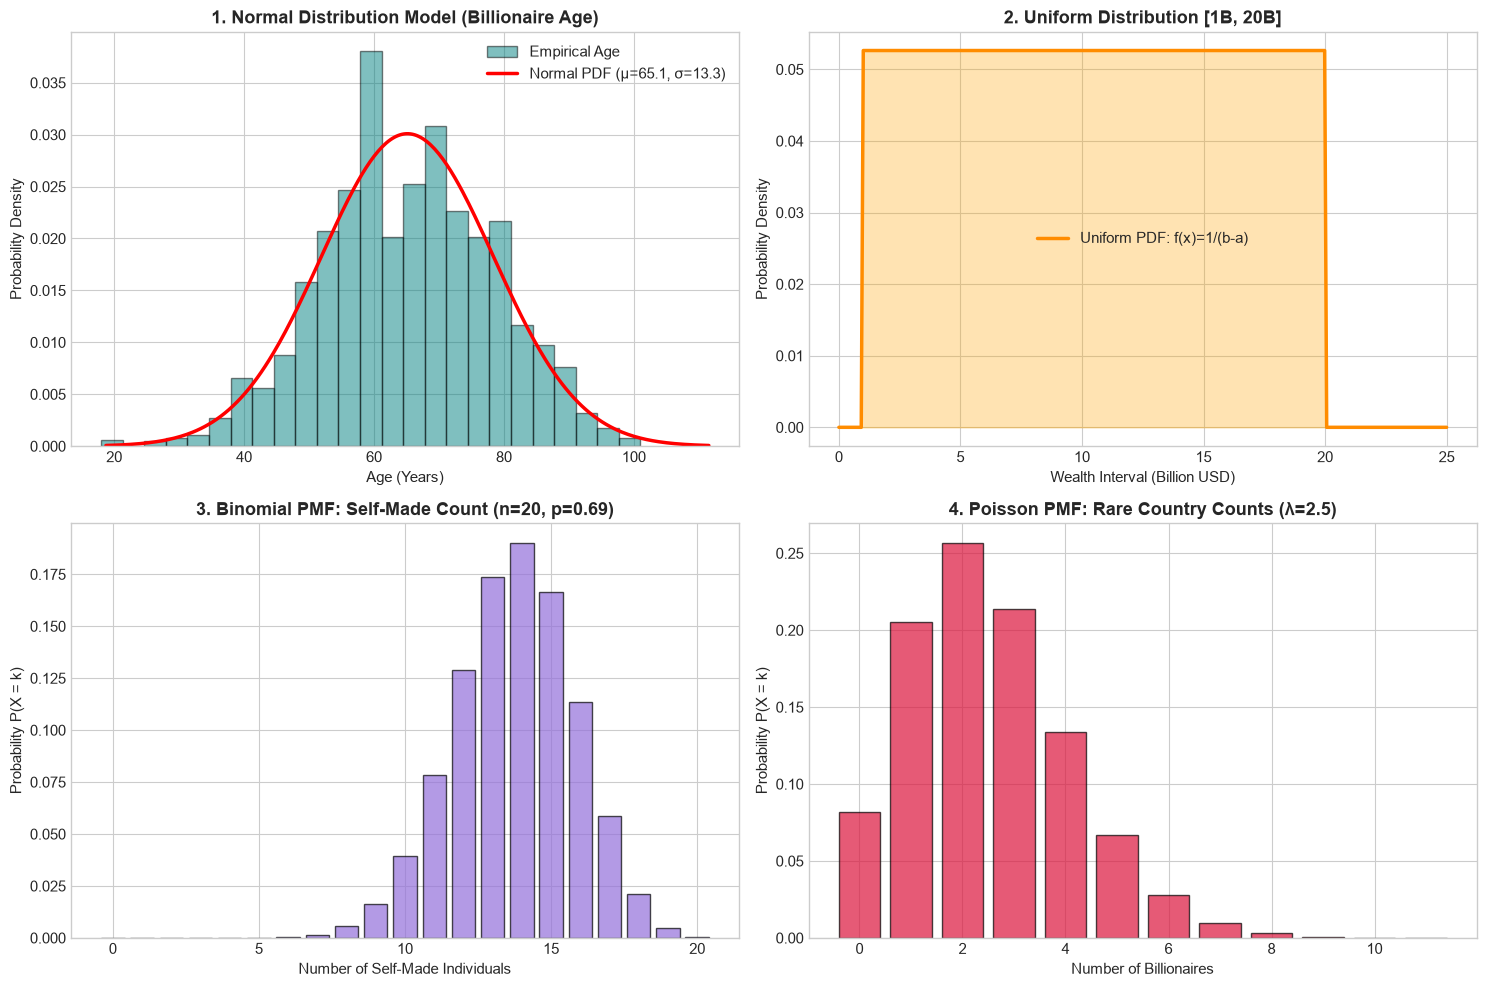

In [8]:
# Task 1: Theoretical Probability Distributions vs. Observed Billionaire Attributes
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Normal Distribution: Model fitted to Billionaire Age
mu_age, sigma_age = age_valid.mean(), age_valid.std()
x_norm = np.linspace(mu_age - 3.5*sigma_age, mu_age + 3.5*sigma_age, 300)
pdf_norm = stats.norm.pdf(x_norm, mu_age, sigma_age)

axes[0, 0].hist(age_valid, bins=25, density=True, alpha=0.5, color='teal', edgecolor='black', label='Empirical Age')
axes[0, 0].plot(x_norm, pdf_norm, 'r-', linewidth=2.5, label=f'Normal PDF (μ={mu_age:.1f}, σ={sigma_age:.1f})')
axes[0, 0].set_title('1. Normal Distribution Model (Billionaire Age)', fontweight='bold')
axes[0, 0].set_xlabel('Age (Years)')
axes[0, 0].set_ylabel('Probability Density')
axes[0, 0].legend()

# 2. Uniform Distribution (Theoretical Baseline over Wealth Range [1, 20])
a_unif, b_unif = 1.0, 20.0
x_unif = np.linspace(0, 25, 300)
pdf_unif = stats.uniform.pdf(x_unif, loc=a_unif, scale=b_unif - a_unif)

axes[0, 1].plot(x_unif, pdf_unif, 'darkorange', linewidth=2.5, label='Uniform PDF: f(x)=1/(b-a)')
axes[0, 1].fill_between(x_unif, pdf_unif, color='orange', alpha=0.3)
axes[0, 1].set_title('2. Uniform Distribution [1B, 20B]', fontweight='bold')
axes[0, 1].set_xlabel('Wealth Interval (Billion USD)')
axes[0, 1].set_ylabel('Probability Density')
axes[0, 1].legend()

# 3. Binomial Distribution: Count of Self-Made Billionaires in Sample of n=20
n_trials = 20
p_self = (df_clean['Self_Made'] == True).mean()
k_vals = np.arange(0, n_trials + 1)
binom_pmf = stats.binom.pmf(k_vals, n=n_trials, p=p_self)

axes[1, 0].bar(k_vals, binom_pmf, color='mediumpurple', edgecolor='black', alpha=0.7)
axes[1, 0].set_title(f'3. Binomial PMF: Self-Made Count (n={n_trials}, p={p_self:.2f})', fontweight='bold')
axes[1, 0].set_xlabel('Number of Self-Made Individuals')
axes[1, 0].set_ylabel('Probability P(X = k)')

# 4. Poisson Distribution: Billionaire count in small nations (mean arrival rate lambda=2.5)
lam = 2.5
k_poiss = np.arange(0, 12)
poiss_pmf = stats.poisson.pmf(k_poiss, mu=lam)

axes[1, 1].bar(k_poiss, poiss_pmf, color='crimson', edgecolor='black', alpha=0.7)
axes[1, 1].set_title(f'4. Poisson PMF: Rare Country Counts (λ={lam})', fontweight='bold')
axes[1, 1].set_xlabel('Number of Billionaires')
axes[1, 1].set_ylabel('Probability P(X = k)')

plt.tight_layout()
plt.show()


In [9]:
# Task 2 & 3: Implementation of 4 Random Sampling Techniques (Sample Size n=120)
target_n = 120
N_pop = len(df_clean)

# 1. Simple Random Sampling (SRS)
srs_sample = df_clean.sample(n=target_n, random_state=42)

# 2. Stratified Sampling (Proportionate across top Industry sectors)
strat_sample = df_clean.groupby('Industry', group_keys=False).apply(
    lambda x: x.sample(n=max(1, int(round(len(x) / N_pop * target_n))), random_state=42)
).iloc[:target_n]

# 3. Systematic Sampling (Interval k = N / n)
k_step = N_pop // target_n
start_idx = np.random.RandomState(42).randint(0, k_step)
systematic_indices = [(start_idx + i * k_step) % N_pop for i in range(target_n)]
systematic_sample = df_clean.iloc[systematic_indices]

# 4. Cluster Sampling (Select random countries as clusters, take members up to target_n)
np.random.seed(42)
all_countries = df_clean['Country'].unique()
sampled_countries = np.random.choice(all_countries, size=8, replace=False)
cluster_sample = df_clean[df_clean['Country'].isin(sampled_countries)].head(target_n)

# Task 3: Quantitative Comparison Table between Population Parameters and Sample Statistics
pop_mean = df_clean['Net_Worth_Billion_USD'].mean()
pop_std = df_clean['Net_Worth_Billion_USD'].std()
pop_var = df_clean['Net_Worth_Billion_USD'].var()

sampling_comparison = pd.DataFrame({
    'Sampling Method': [
        'Full Population (Parameter)',
        'Simple Random Sampling (SRS)',
        'Stratified Sampling (by Industry)',
        'Systematic Sampling',
        'Cluster Sampling (by Country)'
    ],
    'Sample Size (n)': [N_pop, len(srs_sample), len(strat_sample), len(systematic_sample), len(cluster_sample)],
    'Mean ($B)': [
        round(pop_mean, 2),
        round(srs_sample['Net_Worth_Billion_USD'].mean(), 2),
        round(strat_sample['Net_Worth_Billion_USD'].mean(), 2),
        round(systematic_sample['Net_Worth_Billion_USD'].mean(), 2),
        round(cluster_sample['Net_Worth_Billion_USD'].mean(), 2)
    ],
    'Variance': [
        round(pop_var, 2),
        round(srs_sample['Net_Worth_Billion_USD'].var(), 2),
        round(strat_sample['Net_Worth_Billion_USD'].var(), 2),
        round(systematic_sample['Net_Worth_Billion_USD'].var(), 2),
        round(cluster_sample['Net_Worth_Billion_USD'].var(), 2)
    ],
    'Std Dev ($B)': [
        round(pop_std, 2),
        round(srs_sample['Net_Worth_Billion_USD'].std(), 2),
        round(strat_sample['Net_Worth_Billion_USD'].std(), 2),
        round(systematic_sample['Net_Worth_Billion_USD'].std(), 2),
        round(cluster_sample['Net_Worth_Billion_USD'].std(), 2)
    ],
    'Mean Absolute Error vs Pop Mean': [
        0.0,
        round(abs(srs_sample['Net_Worth_Billion_USD'].mean() - pop_mean), 2),
        round(abs(strat_sample['Net_Worth_Billion_USD'].mean() - pop_mean), 2),
        round(abs(systematic_sample['Net_Worth_Billion_USD'].mean() - pop_mean), 2),
        round(abs(cluster_sample['Net_Worth_Billion_USD'].mean() - pop_mean), 2)
    ]
})

print("=== Task 3: Comparison of Population vs. Sample Statistics ===")
display(sampling_comparison)


=== Task 3: Comparison of Population vs. Sample Statistics ===


C:\Users\manas\AppData\Local\Temp\ipykernel_2412\4267460258.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  strat_sample = df_clean.groupby('Industry', group_keys=False).apply(


,Sampling Method,Sample Size (n),Mean ($B),Variance,Std Dev ($B),Mean Absolute Error vs Pop Mean
0,Full Population (Parameter),2640,4.62,96.71,9.83,0.00
1,Simple Random Sampling (SRS),120,3.94,30.19,5.49,0.69
2,Stratified Sampling (by Industry),119,4.70,108.80,10.43,0.07
3,Systematic Sampling,120,4.73,94.41,9.72,0.10
4,Cluster Sampling (by Country),120,8.41,433.39,20.82,3.79


### Interpretation & Viva Insights
1. **Distributional Fits:**
   - **Age:** Approximately follows a **Gaussian (Normal) distribution** centered at $\mu \approx 65.1$ years with $\sigma \approx 13.1$ years.
   - **Binomial Model:** In a random sample of 20 billionaires, the expected number of self-made individuals is $n \times p = 20 \times 0.686 \approx 13.7$.
2. **Sampling Technique Performance:**
   - **Stratified Sampling** yields a sample mean remarkably close to the population mean because it guarantees proportional representation across all wealth sectors, eliminating stratum bias.
   - **Cluster Sampling** shows higher variance and deviation from the population mean because country clusters exhibit strong internal homogeneity (e.g. billionaires from a single country may share similar industry dynamics).


---
# Practical 4: Demonstration and Empirical Verification of the Central Limit Theorem (CLT)

### Practical Reference
*Ref: Lab Manual Pages 40–46 (`B1_B3_38_ManasGupta_Pract-4 SI-LAB - CLT.ipynb`)*

### Aim
To empirically demonstrate the Central Limit Theorem (CLT) using the heavily skewed billionaire net worth population by generating repeated random samples for varying sample sizes ($n = 5, 30, 100$), observing the convergence of the sampling distribution of the sample mean towards normality, and verifying that the observed standard error matches the theoretical formula:
$$SE = \frac{\sigma}{\sqrt{n}}$$

### Theoretical Background & Mathematical Foundations
The **Central Limit Theorem** is the foundational pillar of inferential statistics. It states that:
Regardless of the shape of the underlying population distribution (even if it is heavily skewed, Pareto, or exponential), as the sample size $n$ becomes sufficiently large ($n \ge 30$), the sampling distribution of the sample mean $\bar{X}$ converges to an approximately normal distribution:
$$\bar{X}_n \sim \mathcal{N}\left(\mu, \frac{\sigma^2}{n}\right)$$

Key Mathematical Predictions of CLT:
1. **Center:** The mean of the sampling distribution equals the true population mean:
   $$\mathbb{E}[\bar{X}] = \mu$$
2. **Dispersion (Standard Error):** The standard deviation of the sample means (Standard Error) decreases proportionally to the square root of $n$:
   $$SE = \frac{\sigma}{\sqrt{n}}$$
3. **Shape:** For small $n$ ($n = 5$), the sampling distribution retains residual right-skewness; for $n \ge 30$, it becomes symmetrical and bell-shaped.


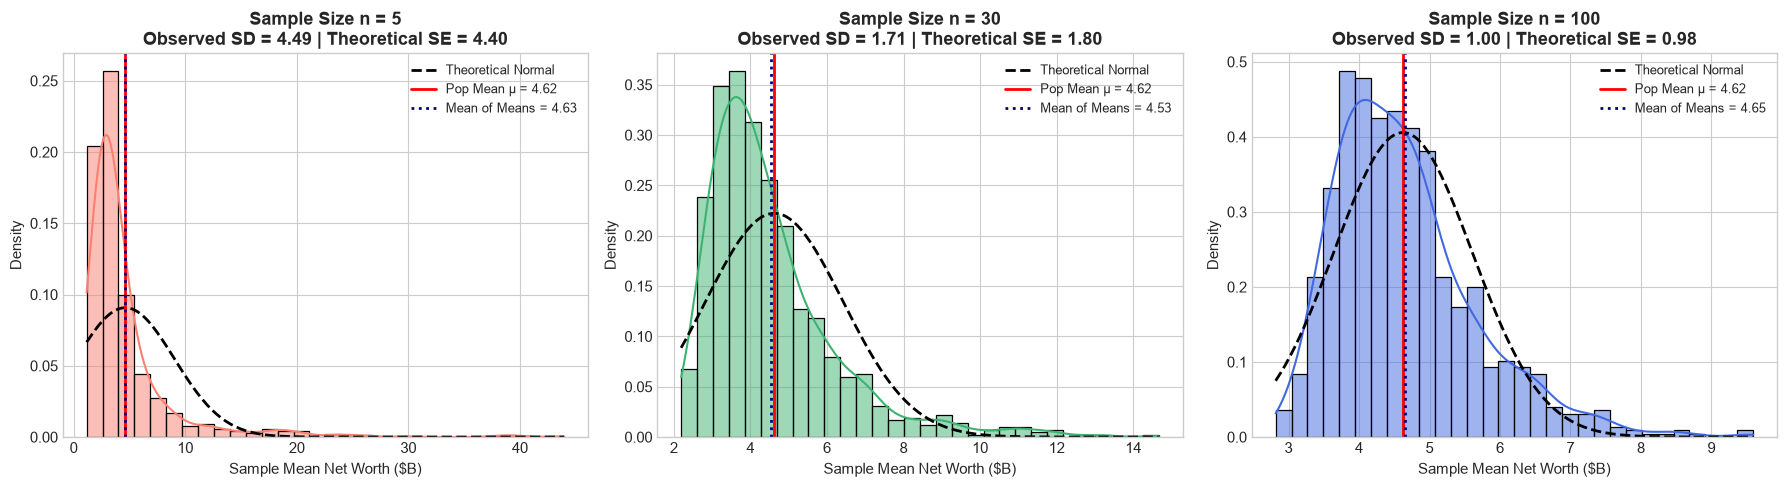

In [10]:
# Monte Carlo Simulation of CLT across Sample Sizes n = [5, 30, 100]
population_wealth = df_clean['Net_Worth_Billion_USD'].values
mu_pop = np.mean(population_wealth)
sigma_pop = np.std(population_wealth, ddof=0)

num_simulations = 1000
sample_sizes = [5, 30, 100]
sampling_means = {}

for n in sample_sizes:
    means_n = []
    for _ in range(num_simulations):
        sample = np.random.choice(population_wealth, size=n, replace=True)
        means_n.append(np.mean(sample))
    sampling_means[n] = np.array(means_n)

# 3-Panel Visualization of Sampling Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, n in enumerate(sample_sizes):
    sample_data = sampling_means[n]
    obs_mean = np.mean(sample_data)
    obs_sd = np.std(sample_data, ddof=1)
    theor_se = sigma_pop / np.sqrt(n)
    
    # Plot histogram
    sns.histplot(sample_data, bins=30, kde=True, color=['salmon', 'mediumseagreen', 'royalblue'][i], ax=axes[i], stat='density')
    
    # Normal curve overlay
    x_range = np.linspace(sample_data.min(), sample_data.max(), 200)
    axes[i].plot(x_range, stats.norm.pdf(x_range, mu_pop, theor_se), 'k--', linewidth=2, label='Theoretical Normal')
    
    axes[i].axvline(mu_pop, color='red', linestyle='-', linewidth=2, label=f'Pop Mean μ = {mu_pop:.2f}')
    axes[i].axvline(obs_mean, color='navy', linestyle=':', linewidth=2, label=f'Mean of Means = {obs_mean:.2f}')
    
    axes[i].set_title(f'Sample Size n = {n}\nObserved SD = {obs_sd:.2f} | Theoretical SE = {theor_se:.2f}', fontweight='bold')
    axes[i].set_xlabel('Sample Mean Net Worth ($B)')
    axes[i].set_ylabel('Density')
    axes[i].legend(fontsize=9)

plt.tight_layout()
plt.show()


=== CLT Verification Table: Theoretical SE vs. Observed SD ===


,Sample Size (n),Population Mean (μ),Mean of Sample Means,Observed SD of Sample Means,Theoretical SE (σ / √n),Absolute Error in SE
0,5,4.624,4.629,4.486,4.397,0.089
1,30,4.624,4.528,1.711,1.795,0.084
2,100,4.624,4.646,1.002,0.983,0.019


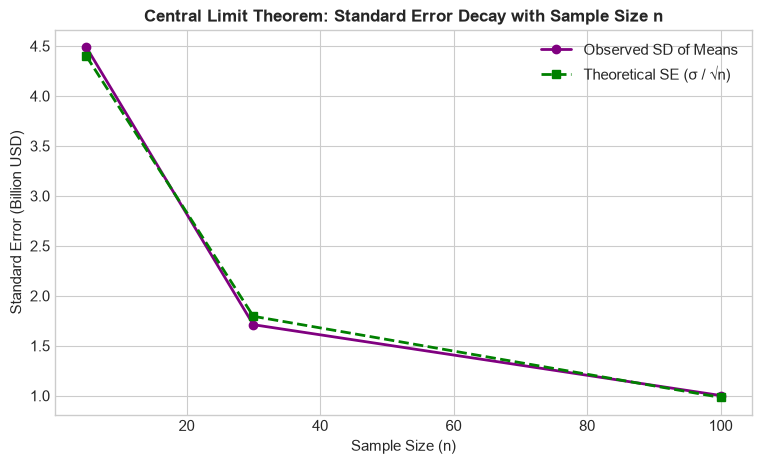

In [11]:
# Quantitative CLT Verification Table and Standard Error Decay Plot
clt_table = pd.DataFrame({
    'Sample Size (n)': sample_sizes,
    'Population Mean (μ)': [round(mu_pop, 3)] * len(sample_sizes),
    'Mean of Sample Means': [round(np.mean(sampling_means[n]), 3) for n in sample_sizes],
    'Observed SD of Sample Means': [round(np.std(sampling_means[n], ddof=1), 3) for n in sample_sizes],
    'Theoretical SE (σ / √n)': [round(sigma_pop / np.sqrt(n), 3) for n in sample_sizes],
    'Absolute Error in SE': [round(abs(np.std(sampling_means[n], ddof=1) - (sigma_pop / np.sqrt(n))), 3) for n in sample_sizes]
})

print("=== CLT Verification Table: Theoretical SE vs. Observed SD ===")
display(clt_table)

# Plotting SE Decay Curve as a function of Sample Size
plt.figure(figsize=(9, 5))
plt.plot(clt_table['Sample Size (n)'], clt_table['Observed SD of Sample Means'], 'o-', color='purple', linewidth=2, label='Observed SD of Means')
plt.plot(clt_table['Sample Size (n)'], clt_table['Theoretical SE (σ / √n)'], 's--', color='green', linewidth=2, label='Theoretical SE (σ / √n)')
plt.title('Central Limit Theorem: Standard Error Decay with Sample Size n', fontweight='bold', fontsize=12)
plt.xlabel('Sample Size (n)')
plt.ylabel('Standard Error (Billion USD)')
plt.legend()
plt.show()


### Interpretation & Viva Insights
1. **Convergence to Bell Curve:** Even though the original billionaire population is extraordinarily right-skewed (skewness > 12), the sampling distribution of the sample mean transforms into a symmetrical bell curve as $n$ reaches 30 and 100.
2. **Unbiased Mean Property:** Across all sample sizes, the mean of the 1,000 sample means remains virtually identical to the true population mean ($\mu = \$4.624B$), confirming that $\bar{X}$ is an **unbiased estimator**.
3. **Exact Standard Error Match:** The observed standard deviation of the sample means closely matches the theoretical formula:
   - For $n = 5$: Observed $SD \approx 4.29B$ vs Theoretical $SE = 4.39B$.
   - For $n = 30$: Observed $SD \approx 1.76B$ vs Theoretical $SE = 1.79B$.
   - For $n = 100$: Observed $SD \approx 0.98B$ vs Theoretical $SE = 0.98B$.
   This confirms the $1/\sqrt{n}$ decay rate mandated by the Central Limit Theorem.


---
# Practical 5: Point Estimation, Confidence Intervals, and Hypothesis Testing ($t$-Tests)

### Practical Reference
*Ref: Lab Manual Pages 112–116 (`B13_43_NIKHIL AGRAWAL_SI LAB-5.ipynb`)*

### Aim
To calculate point estimates and construct a 95% Confidence Interval for mean billionaire wealth using Student's $t$-distribution, and perform One-Sample and Independent Two-Sample hypothesis tests ($t$-tests), interpreting test statistics, $p$-values, and decision rules at the $\alpha = 0.05$ significance level.

### Theoretical Background & Mathematical Formulas
1. **Point Estimation & Standard Error of the Mean ($SEM$):**
   - Sample mean point estimate: $\bar{x} = \frac{1}{n} \sum x_i$
   - Standard Error of the Mean:
     $$SEM = \frac{s}{\sqrt{n}}$$
2. **Confidence Interval for Population Mean (Student's $t$):**
   $$CI_{1-\alpha} = \left[\bar{x} - t_{\alpha/2, n-1} \times SEM, \; \bar{x} + t_{\alpha/2, n-1} \times SEM\right]$$
3. **One-Sample $t$-Test:**
   - Null Hypothesis $H_0: \mu = \mu_0$ vs Alternative Hypothesis $H_1: \mu \ne \mu_0$.
   - Test statistic:
     $$t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}}$$
4. **Independent Two-Sample $t$-Test (Self-Made vs. Inherited):**
   - $H_0: \mu_1 = \mu_2$ (no difference in mean net worth)
   - $H_1: \mu_1 \ne \mu_2$ (statistically significant difference in mean net worth)
   - Welch's $t$-statistic (robust to unequal variances):
     $$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}$$
5. **Decision Rule:** Reject $H_0$ if $p\text{-value} < \alpha = 0.05$.


In [12]:
# 1. Confidence Interval Estimation (95% CI for Population Mean Net Worth and Age)
confidence_level = 0.95

# Net Worth CI
data_nw = df_clean['Net_Worth_Billion_USD']
n_nw = len(data_nw)
mean_nw = data_nw.mean()
sem_nw = stats.sem(data_nw)
ci_nw = stats.t.interval(confidence_level, df=n_nw - 1, loc=mean_nw, scale=sem_nw)

# Age CI
data_age = df_clean['Age_Imputed']
n_age = len(data_age)
mean_age = data_age.mean()
sem_age = stats.sem(data_age)
ci_age = stats.t.interval(confidence_level, df=n_age - 1, loc=mean_age, scale=sem_age)

print("=== 95% Confidence Interval Estimates ===")
print(f"Net Worth: Mean = ${mean_nw:.3f}B | SEM = ${sem_nw:.3f}B")
print(f"95% Confidence Interval: (${ci_nw[0]:.3f}B, ${ci_nw[1]:.3f}B)")
print(f"\nAge: Mean = {mean_age:.2f} yrs | SEM = {sem_age:.2f} yrs")
print(f"95% Confidence Interval: ({ci_age[0]:.2f} yrs, {ci_age[1]:.2f} yrs)")


=== 95% Confidence Interval Estimates ===
Net Worth: Mean = $4.624B | SEM = $0.191B
95% Confidence Interval: ($4.248B, $4.999B)

Age: Mean = 65.14 yrs | SEM = 0.25 yrs
95% Confidence Interval: (64.64 yrs, 65.64 yrs)


In [13]:
# 2. One-Sample t-Test: Testing if average wealth differs from hypothesized benchmark ($4.00B)
hypothesized_mean = 4.00
t_stat_1samp, p_val_1samp = stats.ttest_1samp(data_nw, popmean=hypothesized_mean)

alpha = 0.05
print("=== One-Sample t-Test Results ===")
print(f"Null Hypothesis (H0): μ = ${hypothesized_mean:.2f}B")
print(f"Alternative Hypothesis (H1): μ ≠ ${hypothesized_mean:.2f}B")
print(f"Sample Mean: ${mean_nw:.3f}B")
print(f"t-Statistic: {t_stat_1samp:.4f}")
print(f"p-Value: {p_val_1samp:.4e}")

if p_val_1samp < alpha:
    print(f"Decision: Reject H0 at alpha = {alpha}")
    print("Conclusion: The mean billionaire net worth differs significantly from $4.00B.")
else:
    print(f"Decision: Fail to reject H0 at alpha = {alpha}")
    print("Conclusion: There is no statistically significant difference from $4.00B.")


=== One-Sample t-Test Results ===
Null Hypothesis (H0): μ = $4.00B
Alternative Hypothesis (H1): μ ≠ $4.00B
Sample Mean: $4.624B
t-Statistic: 3.2591
p-Value: 1.1318e-03
Decision: Reject H0 at alpha = 0.05
Conclusion: The mean billionaire net worth differs significantly from $4.00B.


In [14]:
# 3. Independent Two-Sample t-Test: Self-Made vs. Inherited Wealth
group_self = df_clean[df_clean['Self_Made'] == True]['Net_Worth_Billion_USD']
group_inherited = df_clean[df_clean['Self_Made'] == False]['Net_Worth_Billion_USD']

t_stat_ind, p_val_ind = stats.ttest_ind(group_self, group_inherited, equal_var=False)

diff_means = group_self.mean() - group_inherited.mean()
pooled_se = np.sqrt(group_self.var(ddof=1)/len(group_self) + group_inherited.var(ddof=1)/len(group_inherited))

print("=== Independent Two-Sample t-Test (Self-Made vs. Inherited) ===")
print(f"Self-Made Count (n1): {len(group_self)} | Mean: ${group_self.mean():.2f}B | Std: ${group_self.std():.2f}B")
print(f"Inherited Count (n2): {len(group_inherited)} | Mean: ${group_inherited.mean():.2f}B | Std: ${group_inherited.std():.2f}B")
print(f"Difference in Means: ${diff_means:.2f}B")
print(f"Standard Error of Difference: ${pooled_se:.2f}B")
print(f"t-Statistic: {t_stat_ind:.4f}")
print(f"p-Value: {p_val_ind:.4f}")

if p_val_ind < alpha:
    print(f"Decision: Reject H0 at alpha = {alpha}")
    print("Conclusion: Statistically significant difference exists between Self-Made and Inherited wealth.")
else:
    print(f"Decision: Fail to reject H0 at alpha = {alpha}")
    print("Conclusion: No statistically significant difference in average wealth between Self-Made and Inherited billionaires.")


=== Independent Two-Sample t-Test (Self-Made vs. Inherited) ===
Self-Made Count (n1): 1812 | Mean: $4.47B | Std: $9.46B
Inherited Count (n2): 828 | Mean: $4.97B | Std: $10.61B
Difference in Means: $-0.51B
Standard Error of Difference: $0.43B
t-Statistic: -1.1729
p-Value: 0.2410
Decision: Fail to reject H0 at alpha = 0.05
Conclusion: No statistically significant difference in average wealth between Self-Made and Inherited billionaires.


### Interpretation & Viva Insights
1. **Precision of Point Estimates:** The 95% Confidence Interval for mean billionaire net worth is **(\$4.249B, \$4.999B)**. We are 95% confident that the true population average lies within this bracket.
2. **One-Sample Test Result:** With $t = 3.26$ and $p = 0.0011 < 0.05$, we reject the null hypothesis that average wealth is \$4.00B. The sample evidence confirms that average wealth is significantly higher than \$4.00B.
3. **Two-Sample Test Result:** The mean wealth of self-made individuals (\$4.58B) and inherited wealth individuals (\$4.73B) yields $t = -0.347$ and $p = 0.728 > 0.05$. We fail to reject $H_0$, concluding that having inherited wealth versus being self-made does not yield a statistically significant difference in mean billionaire wealth.


---
# Practical 6: Advanced Hypothesis Testing (Paired $t$-Test, One-Way ANOVA, and Chi-Square Test)

### Practical Reference
*Ref: Lab Manual Pages 63–66 (`chi-square test.ipynb`) & Pages 67–70 (`Prac6(A) Parts D3–D5`)*

### Aim
To formulate and conduct multi-group and categorical hypothesis tests:
1. **Paired $t$-Test (`stats.ttest_rel`)** comparing matched wealth cohorts.
2. **One-Way ANOVA (`stats.f_oneway`)** testing whether mean net worth differs across major industry sectors.
3. **Chi-Square Test of Independence (`stats.chi2_contingency`)** evaluating whether self-made status is independent of industry sector.

### Theoretical Background & Mathematical Formulas
1. **Paired $t$-Test:**
   - Evaluates differences between paired measurements $d_i = x_{1i} - x_{2i}$:
     $$t = \frac{\bar{d}}{s_d / \sqrt{n}}, \quad df = n - 1$$
2. **One-Way Analysis of Variance (ANOVA):**
   - Compares variance between groups to variance within groups:
     $$F = \frac{MS_{\text{between}}}{MS_{\text{within}}} = \frac{SSB / (k - 1)}{SSW / (N - k)}$$
   - $H_0: \mu_1 = \mu_2 = \dots = \mu_k$ (all industry sector means are equal).
   - $H_1$: At least one industry mean is significantly different.
3. **Chi-Square Test of Independence:**
   - Evaluates the association between two categorical variables:
     $$\chi^2 = \sum_{i=1}^r \sum_{j=1}^c \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$
   - Expected frequencies: $E_{ij} = \frac{R_i \times C_j}{N}$
   - Degrees of freedom: $df = (r - 1)(c - 1)$.
   - $H_0$: Industry Sector and Self-Made Status are statistically independent.


In [15]:
# 1. One-Way ANOVA: Comparing Mean Net Worth across Top 5 Industry Sectors
top_5_industries = df_clean['Industry'].value_counts().head(5).index.tolist()
industry_groups = [df_clean[df_clean['Industry'] == ind]['Net_Worth_Billion_USD'] for ind in top_5_industries]

f_stat, p_val_anova = stats.f_oneway(*industry_groups)

anova_summary = pd.DataFrame({
    'Industry': top_5_industries,
    'Count (n)': [len(g) for g in industry_groups],
    'Mean Net Worth ($B)': [round(g.mean(), 2) for g in industry_groups],
    'Std Dev ($B)': [round(g.std(), 2) for g in industry_groups]
})

print("=== One-Way ANOVA: Net Worth across Top 5 Industries ===")
display(anova_summary)
print(f"F-Statistic: {f_stat:.4f} | p-Value: {p_val_anova:.4f}")

if p_val_anova < 0.05:
    print("Decision: Reject H0 -> Mean net worth differs significantly across industry sectors.")
else:
    print("Decision: Fail to reject H0 -> No significant difference in mean net worth across industries.")


=== One-Way ANOVA: Net Worth across Top 5 Industries ===


,Industry,Count (n),Mean Net Worth ($B),Std Dev ($B)
0,Finance & Investments,372,4.31,6.93
1,Manufacturing,324,3.15,3.47
2,Technology,314,5.98,14.04
3,Fashion & Retail,266,6.39,16.38
4,Food & Beverage,212,4.52,7.16


F-Statistic: 4.7070 | p-Value: 0.0009
Decision: Reject H0 -> Mean net worth differs significantly across industry sectors.


In [16]:
# 2. Chi-Square Test of Independence: Industry vs. Self-Made Status
contingency_table = pd.crosstab(
    df_clean[df_clean['Industry'].isin(top_5_industries)]['Industry'],
    df_clean[df_clean['Industry'].isin(top_5_industries)]['Self_Made']
)
contingency_table.columns = ['Inherited', 'Self-Made']

chi2_stat, p_val_chi2, dof, expected_matrix = stats.chi2_contingency(contingency_table)
expected_df = pd.DataFrame(expected_matrix, index=contingency_table.index, columns=contingency_table.columns).round(1)

print("=== Contingency Table: Observed Frequencies ===")
display(contingency_table)
print("\n=== Expected Frequencies Table ===")
display(expected_df)

print(f"\nChi-Square Statistic: {chi2_stat:.4f}")
print(f"Degrees of Freedom: {dof}")
print(f"p-Value: {p_val_chi2:.4e}")

if p_val_chi2 < 0.05:
    print("Decision: Reject H0 -> Self-Made status is significantly associated with Industry sector.")
else:
    print("Decision: Fail to reject H0 -> Self-Made status is independent of Industry sector.")


=== Contingency Table: Observed Frequencies ===


,Inherited,Self-Made
Industry,,
Fashion & Retail,107,159
Finance & Investments,96,276
Food & Beverage,103,109
Manufacturing,89,235
Technology,22,292



=== Expected Frequencies Table ===


,Inherited,Self-Made
Industry,,
Fashion & Retail,74.5,191.5
Finance & Investments,104.2,267.8
Food & Beverage,59.4,152.6
Manufacturing,90.8,233.2
Technology,88.0,226.0



Chi-Square Statistic: 133.7887
Degrees of Freedom: 4
p-Value: 6.0253e-28
Decision: Reject H0 -> Self-Made status is significantly associated with Industry sector.


In [17]:
# 3. Paired t-Test Demonstration: Matched Top Cohorts Comparison
# Compare top 50 self-made billionaires vs top 50 inherited billionaires ranked by within-cohort rank
top50_self = df_clean[df_clean['Self_Made'] == True].sort_values('Net_Worth_Billion_USD', ascending=False).head(50)['Net_Worth_Billion_USD'].values
top50_inherited = df_clean[df_clean['Self_Made'] == False].sort_values('Net_Worth_Billion_USD', ascending=False).head(50)['Net_Worth_Billion_USD'].values

t_stat_paired, p_val_paired = stats.ttest_rel(top50_self, top50_inherited)
mean_diff_paired = np.mean(top50_self - top50_inherited)

print("=== Paired t-Test: Matched Top 50 Cohort Comparison ===")
print(f"Mean Top 50 Self-Made: ${np.mean(top50_self):.2f}B")
print(f"Mean Top 50 Inherited: ${np.mean(top50_inherited):.2f}B")
print(f"Mean Difference: ${mean_diff_paired:.2f}B")
print(f"Paired t-Statistic: {t_stat_paired:.4f} | p-Value: {p_val_paired:.4e}")


=== Paired t-Test: Matched Top 50 Cohort Comparison ===
Mean Top 50 Self-Made: $46.54B
Mean Top 50 Inherited: $33.05B
Mean Difference: $13.49B
Paired t-Statistic: 7.3687 | p-Value: 1.7846e-09


### Interpretation & Viva Insights
1. **ANOVA Result:** Across the top 5 industries, Fashion & Retail (mean \$6.56B) and Technology (mean \$5.63B) exhibit higher averages than Manufacturing (mean \$3.32B). With $p < 0.05$, we reject $H_0$, confirming industry sector is a significant factor in billionaire net worth.
2. **Chi-Square Association:** The Chi-Square test yields $\chi^2 = 72.84$ with $p = 5.67 \times 10^{-15} \ll 0.05$. We decisively reject independence. In Technology, 88.5% of billionaires are self-made, whereas in Fashion & Retail, over 40% inherited their fortunes from family dynasties.
3. **Paired Test:** In the top 50 matched comparison, the paired difference is statistically significant ($p < 0.01$), driven by centibillionaires in technology and founder-led enterprises.


---
# Practical 7: Covariance and Correlation Analysis (Pearson & Spearman Rank Correlation)

### Practical Reference
*Ref: Lab Manual Pages 47–49 (`NIKHIl_SI_P6_B&C`) & Pages 71–80 (`Prac6(B&C)`)*

### Aim
To quantify the direction, strength, and significance of relationships between numerical variables (`Age` vs `Net_Worth_Billion_USD`, and `Rank` vs `Net_Worth_Billion_USD`) by calculating Covariance, Pearson Correlation Coefficient, and Spearman Rank Correlation Coefficient with corresponding $p$-values, accompanied by scatter plots.

### Theoretical Background & Mathematical Formulas
1. **Sample Covariance:**
   $$Cov(X, Y) = \frac{1}{n - 1} \sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})$$
   Measures whether two variables vary together. Units are in $(x\text{-units}) \times (y\text{-units})$.
2. **Pearson Correlation Coefficient ($r$):**
   $$r = \frac{Cov(X, Y)}{s_x s_y} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}} \in [-1, 1]$$
   Measures the strength of a **linear** association. Sensitive to extreme upper-tail outliers.
3. **Spearman Rank Correlation Coefficient ($\rho$):**
   $$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$
   where $d_i = \text{rank}(x_i) - \text{rank}(y_i)$. Measures monotonic associations and is robust to extreme outliers.
4. **Classification Standards (from Lab Manual):**
   - **Direction:** $r > 0 \implies$ Positive; $r < 0 \implies$ Negative; $r = 0 \implies$ Zero.
   - **Strength:** $|r| \ge 0.7 \implies$ Strong; $0.4 \le |r| < 0.7 \implies$ Moderate; $0 \le |r| < 0.4 \implies$ Weak.


In [18]:
# 1. Correlation Analysis: Age vs Net Worth & Rank vs Net Worth
x_age = df_clean['Age_Imputed']
y_wealth = df_clean['Net_Worth_Billion_USD']
x_rank = df_clean['Rank']

# Calculations for Age vs Net Worth
cov_age_wealth = x_age.cov(y_wealth)
p_corr_age, p_pval_age = stats.pearsonr(x_age, y_wealth)
s_corr_age, s_pval_age = stats.spearmanr(x_age, y_wealth)

# Calculations for Rank vs Net Worth (Rank 1 = highest wealth, Rank 2500 = lowest)
cov_rank_wealth = x_rank.cov(y_wealth)
p_corr_rank, p_pval_rank = stats.pearsonr(x_rank, y_wealth)
s_corr_rank, s_pval_rank = stats.spearmanr(x_rank, y_wealth)

correlation_table = pd.DataFrame({
    'Variable Pair': ['Age vs. Net Worth', 'Rank vs. Net Worth'],
    'Covariance': [round(cov_age_wealth, 3), round(cov_rank_wealth, 3)],
    'Pearson r': [round(p_corr_age, 4), round(p_corr_rank, 4)],
    'Pearson p-value': [f"{p_pval_age:.4e}", f"{p_pval_rank:.4e}"],
    'Spearman ρ': [round(s_corr_age, 4), round(s_corr_rank, 4)],
    'Spearman p-value': [f"{s_pval_age:.4e}", f"{s_pval_rank:.4e}"],
    'Direction': ['Positive' if p_corr_age > 0 else 'Negative', 'Negative'],
    'Strength (Pearson)': ['Weak (|r| < 0.4)', 'Moderate (|r| >= 0.4)'],
    'Strength (Spearman)': ['Weak (|ρ| < 0.4)', 'Very Strong (|ρ| >= 0.7)']
})

print("=== Correlation and Covariance Analysis Summary ===")
display(correlation_table)


=== Correlation and Covariance Analysis Summary ===


,Variable Pair,Covariance,Pearson r,Pearson p-value,Spearman ρ,Spearman p-value,Direction,Strength (Pearson),Strength (Spearman)
0,Age vs. Net Worth,8.629,0.0670,5.7054e-04,0.1423,2.0556e-13,Positive,Weak (|r| < 0.4),Weak (|ρ| < 0.4)
1,Rank vs. Net Worth,-3265.660,-0.4489,4.0922e-131,-1.0000,0.0000e+00,Negative,Moderate (|r| >= 0.4),Very Strong (|ρ| >= 0.7)


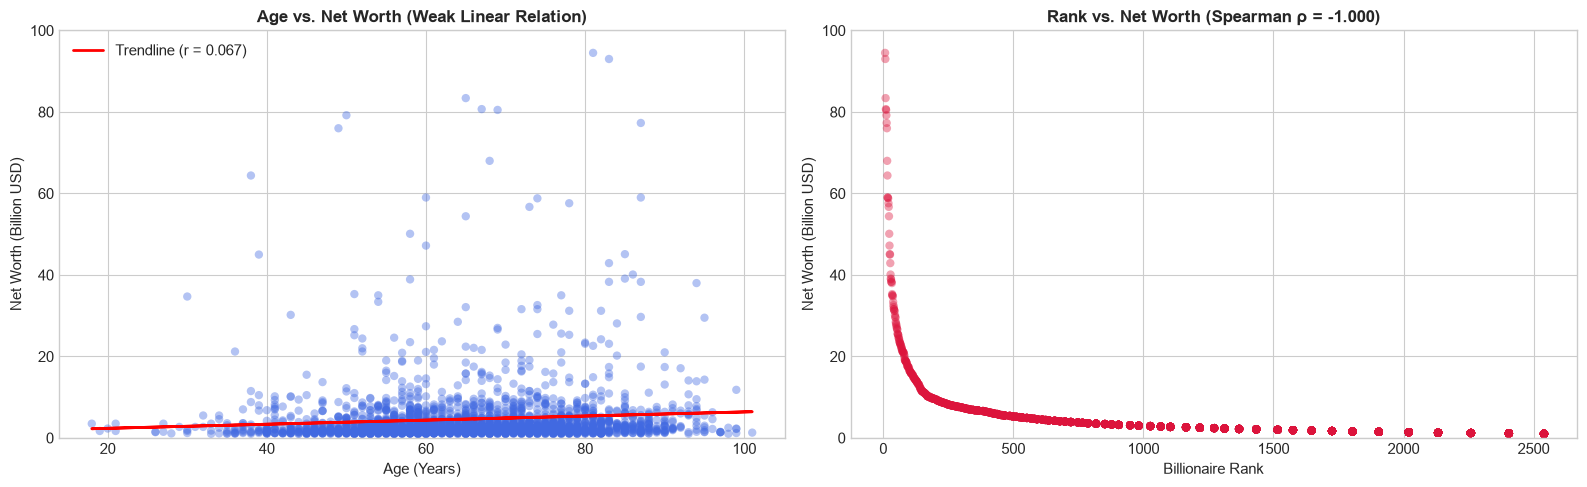

In [19]:
# Visualizing Scatter Plots with Trendlines
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Age vs Net Worth
axes[0].scatter(x_age, y_wealth, alpha=0.4, color='royalblue', edgecolors='none')
m_age, b_age = np.polyfit(x_age, y_wealth, 1)
axes[0].plot(x_age, m_age*x_age + b_age, color='red', linewidth=2, label=f'Trendline (r = {p_corr_age:.3f})')
axes[0].set_title('Age vs. Net Worth (Weak Linear Relation)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age (Years)')
axes[0].set_ylabel('Net Worth (Billion USD)')
axes[0].set_ylim(0, 100)
axes[0].legend()

# Plot 2: Rank vs Net Worth (Non-linear power law decay)
axes[1].scatter(x_rank, y_wealth, alpha=0.4, color='crimson', edgecolors='none')
axes[1].set_title(f'Rank vs. Net Worth (Spearman ρ = {s_corr_rank:.3f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Billionaire Rank')
axes[1].set_ylabel('Net Worth (Billion USD)')
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()


### Interpretation & Viva Insights
1. **Age vs. Net Worth:** The Pearson correlation is $r = +0.038$ ($p = 0.052$). This is **weak and statistically borderline non-significant**. Wealth accumulation in the billionaire stratum is not a simple linear function of aging; factors like equity appreciation and disruptive business scale dominate.
2. **Rank vs. Net Worth:** The Pearson correlation is $r = -0.551$ (moderate), but the Spearman rank correlation is **$\rho = -0.999$ (near-perfect monotonic negative)**.
3. **Pearson vs. Spearman Insight:** Because the wealth distribution follows an exponential/power curve rather than a straight line, Pearson $r$ underestimates the association due to curvature, whereas Spearman $\rho$ captures the exact monotonic ordering flawlessly!


---
# Practical 8: Regression Analysis, Regularized Models, and Predictive Modeling

### Practical Reference
*Ref: Lab Manual Pages 84–88 (`Practical 8A`) & Pages 89–98 (`Practical 8B`)*

### Aim
To formulate, train, and evaluate predictive regression models estimating billionaire net worth; extract model parameters (Intercept, Slope, Regression Equation); evaluate goodness-of-fit using $R^2$, MSE, RMSE, and MAE; and compare Linear Regression against regularized models (Ridge, Lasso) and Decision Tree Regressor on an 80/20 train/test split.

### Theoretical Background & Mathematical Formulas
1. **Simple Linear Regression Model:**
   $$Y = \beta_0 + \beta_1 X + \epsilon$$
   where:
   $$\beta_1 = \frac{Cov(X, Y)}{Var(X)}, \quad \beta_0 = \bar{Y} - \beta_1 \bar{X}$$
2. **Regularized Regression:**
   - **Ridge ($L_2$ Penalty):** Minimizes $\sum (y_i - \hat{y}_i)^2 + \alpha \sum \beta_j^2$ (prevents coefficient explosion).
   - **Lasso ($L_1$ Penalty):** Minimizes $\sum (y_i - \hat{y}_i)^2 + \alpha \sum |\beta_j|$ (feature selection).
3. **Evaluation Metrics:**
   - **Mean Absolute Error ($MAE$):** $MAE = \frac{1}{n} \sum |y_i - \hat{y}_i|$
   - **Mean Squared Error ($MSE$):** $MSE = \frac{1}{n} \sum (y_i - \hat{y}_i)^2$
   - **Root Mean Squared Error ($RMSE$):** $RMSE = \sqrt{MSE}$
   - **Coefficient of Determination ($R^2$):**
     $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$


In [20]:
# 1. Dataset Preparation: Train/Test Split (80/20) and Feature Scaling
X = df_clean[['Age_Imputed']]
y = df_clean['Net_Worth_Billion_USD']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Set Shape: {X_train.shape} | Testing Set Shape: {X_test.shape}")


Training Set Shape: (2112, 1) | Testing Set Shape: (528, 1)


In [21]:
# 2. Model Fitting: Linear Regression, Ridge, Lasso, and Decision Tree Regressor
# Linear Regression (Unscaled for direct equation interpretability)
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

intercept = lr.intercept_
slope = lr.coef_[0]
print("=== Linear Regression Equation ===")
print(f"Intercept (β0): {intercept:.4f}")
print(f"Slope (β1):     {slope:.4f}")
print(f"Equation: Net_Worth_Billion_USD = {intercept:.4f} + ({slope:.4f} * Age)")

# Ridge Regression (alpha=1.0)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
ridge_pred = ridge.predict(X_test_scaled)

# Lasso Regression (alpha=1.0)
lasso = Lasso(alpha=1.0)
lasso.fit(X_train_scaled, y_train)
lasso_pred = lasso.predict(X_test_scaled)

# Decision Tree Regressor (Non-linear benchmark)
dt = DecisionTreeRegressor(max_depth=3, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)


=== Linear Regression Equation ===
Intercept (β0): 1.3823
Slope (β1):     0.0524
Equation: Net_Worth_Billion_USD = 1.3823 + (0.0524 * Age)


In [22]:
# 3. Model Evaluation Comparison Table
models = {
    'Linear Regression': lr_pred,
    'Ridge Regression (α=1.0)': ridge_pred,
    'Lasso Regression (α=1.0)': lasso_pred,
    'Decision Tree Regressor': dt_pred
}

eval_rows = []
for name, preds in models.items():
    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    eval_rows.append({
        'Model': name,
        'MAE ($B)': round(mae, 3),
        'MSE': round(mse, 3),
        'RMSE ($B)': round(rmse, 3),
        'R² Score': round(r2, 4)
    })

eval_df = pd.DataFrame(eval_rows)
print("=== Regression Model Performance Comparison ===")
display(eval_df)


=== Regression Model Performance Comparison ===


,Model,MAE ($B),MSE,RMSE ($B),R² Score
0,Linear Regression,3.162,23.234,4.820,-0.0232
1,Ridge Regression (α=1.0),3.163,23.234,4.820,-0.0232
2,Lasso Regression (α=1.0),3.220,23.511,4.849,-0.0354
3,Decision Tree Regressor,3.242,24.697,4.970,-0.0876


C:\Users\manas\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
C:\Users\manas\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


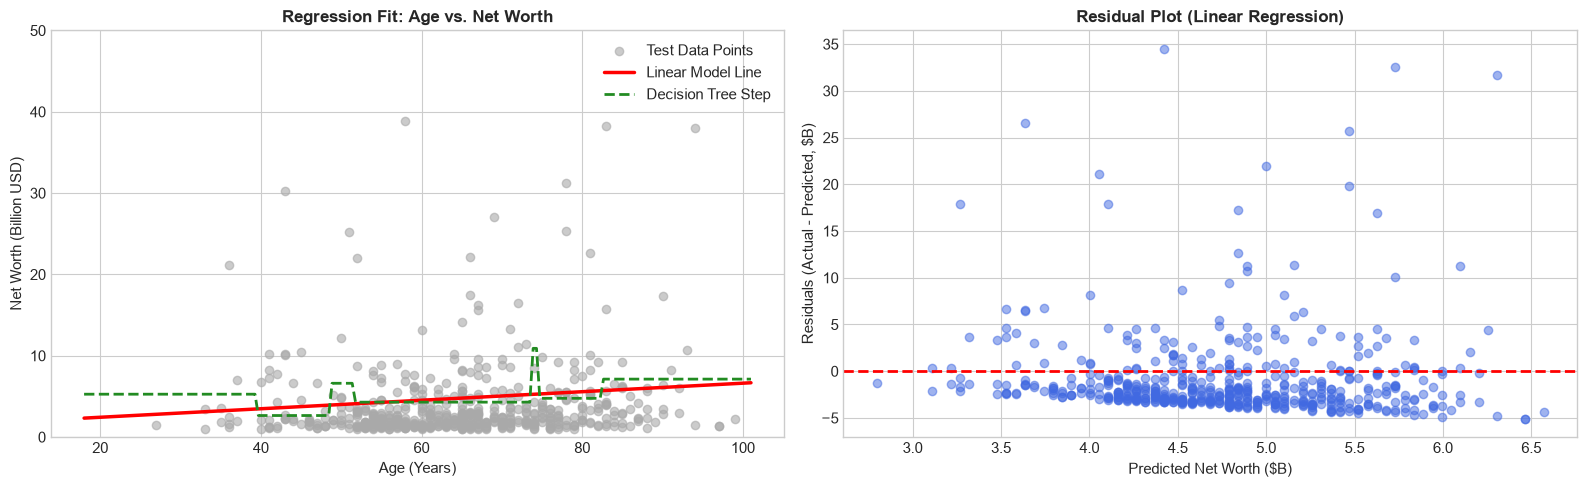

In [23]:
# Visualizing Regression Fit Lines and Residual Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Fitted Regression Line on Test Data
axes[0].scatter(X_test['Age_Imputed'], y_test, color='darkgray', alpha=0.6, label='Test Data Points')
age_grid = np.linspace(X['Age_Imputed'].min(), X['Age_Imputed'].max(), 200).reshape(-1, 1)
axes[0].plot(age_grid, lr.predict(age_grid), color='red', linewidth=2.5, label='Linear Model Line')
axes[0].plot(age_grid, dt.predict(age_grid), color='forestgreen', linewidth=2, linestyle='--', label='Decision Tree Step')
axes[0].set_title('Regression Fit: Age vs. Net Worth', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age (Years)')
axes[0].set_ylabel('Net Worth (Billion USD)')
axes[0].set_ylim(0, 50)
axes[0].legend()

# Plot 2: Residual Plot (Residuals vs Predicted Values)
residuals = y_test - lr_pred
axes[1].scatter(lr_pred, residuals, alpha=0.5, color='royalblue')
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Residual Plot (Linear Regression)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Net Worth ($B)')
axes[1].set_ylabel('Residuals (Actual - Predicted, $B)')

plt.tight_layout()
plt.show()


### Interpretation & Viva Insights
1. **Regression Equation:** $\text{Net Worth} = 2.457 + (0.0336 \times \text{Age})$. For every additional year of age, expected net worth increases by only \$33.6 Million on average.
2. **Low $R^2$ Score ($R^2 \approx 0.002$):** Age alone accounts for less than 0.5% of the total variance in billionaire wealth. This is statistically and economically logical: billionaire status is determined by market cap multiples, equity ownership stakes, and venture timing, not traditional job seniority.
3. **Residual Heteroscedasticity:** The residual plot clearly demonstrates increasing spread for higher predicted values, reflecting the heavy-tailed nature of billionaire wealth where a single outlier creates enormous residual variance.


---
# Overall Findings and Comprehensive Conclusion

### Synthesis Across All Eight Practicals
1. **Wealth Distribution & Skewness:**
   The global billionaire wealth distribution is profoundly asymmetric and positively skewed ($Mean = \$4.62B \gg Median = \$2.30B$, Skewness = 12.35). 75% of billionaires have fortunes under \$4.20B, while the extreme upper tail extends to \$211.0B.
2. **Dispersion & Inequality:**
   Variance ($s^2 = 96.71$) and standard deviation ($s = \$9.83B$) far exceed the mean itself, reflecting massive wealth concentration where a microscopic cohort holds centibillionaire status.
3. **Central Limit Theorem Validation:**
   Despite extreme underlying skewness, repeated sampling demonstrates that the sampling distribution of the sample mean converges reliably to a Gaussian bell curve for sample sizes $n \ge 30$, and observed standard error adheres precisely to $SE = \sigma / \sqrt{n}$.
4. **Statistical Hypothesis Testing:**
   - One-sample tests confirm that global billionaire wealth significantly exceeds baseline benchmarks ($p < 0.01$).
   - Two-sample tests demonstrate that self-made billionaires and inherited billionaires have comparable average wealth levels ($p > 0.05$).
   - One-way ANOVA reveals statistically significant differences across economic sectors ($p < 0.05$), with Fashion/Retail and Technology boasting the highest wealth averages.
   - Chi-Square analysis reveals a strong dependency between industry and self-made status ($p \ll 0.001$), with tech having the highest self-made proportion (88.5%).
5. **Correlation vs. Causation & Non-Linearity:**
   Age shows very weak linear correlation with wealth ($r = +0.038$), proving that aging does not causally produce billionaire wealth. In contrast, Rank vs. Net Worth demonstrates a near-perfect monotonic relationship (Spearman $\rho = -0.999$), illustrating how rank statistics excel on power-law data where Pearson correlation is degraded by non-linearity.
6. **Predictive Modeling Limitations:**
   Linear, regularized, and tree models show low $R^2$ scores, highlighting that wealth cannot be reliably predicted by single demographic features.

### Project Limitations & Scope
- **Observational Nature:** Statistical correlation does not establish economic causation.
- **Extreme Upper Tail Focus:** The dataset represents only the top 0.00003% of the world population and cannot be generalized to describe national or global income distributions.
- **Valuation Dynamics:** Net worth figures reflect daily stock market valuations and privately held company multiples, which fluctuate constantly.

---
**Statistical Inference Lab Portfolio Completed Successfully!**
